# ENGR 1451/2451 — Weekly Assignment 5
**10 points**

Practice loading a CSV file, selecting complete observations, calculating correlations, making scatterplots and a correlation heat map, and writing a reusable function to compare individual and grouped data.

**Due:** See Canvas.

Complete the work directly in this notebook. Show your Python code and give brief written explanations where requested.

## What to hand in

Work this assignment with the **course tutor** in the class project. Use the course tutor as your AI help for this assignment; it keeps the record for you, so you do not need to write a separate log.

At the end of each working session, type **"make my record"** in the chat. Copy the block it produces and paste it into the **Session records** cell near the bottom of this notebook.

You do not have to finish in one sitting. To continue later, start a new chat in the same project, state which assignment you are working on and where you stopped, and continue from there. Paste the new session record below the previous one.

Session records are not graded for correctness or for how much help you needed. The code and written answers must still be your own.

## Setup

LE5-2 uses the supplied **`data/penguins.csv`** file. Keep the `data` folder beside this notebook. Use the folder containing the notebook as the working directory. The other exercises retain the embedded synthetic teaching data.

Select observations by conditions, not row positions. Calculate counts and cutoffs from the data. Label scatterplot axes with units. Keep written comments brief and tied to your calculated results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from IPython.display import display

## LE5-1. Compare laptop measurements (3 pts)

Each row describes one laptop. `battery_Wh` is battery capacity in watt-hours, `mass_kg` is mass in kilograms, and `runtime_h` is measured battery runtime in hours. Two entries are missing.

### A. Select complete observations (1 pt)

Create `complete` by selecting the three columns in `feature_cols` and dropping rows missing **any** of them. Report the number of laptops retained and excluded, using counts calculated from the data.

In [2]:
battery_Wh = [36, 42, 45, 48, 54, 60, 63, 66,
              72, 75, 78, 84, 90, 96, np.nan, 80]
laptops = pd.DataFrame({
    "battery_Wh": battery_Wh,
    "mass_kg": [1.2, 1.1, 1.6, 1.2, 1.5, 1.3, 1.4, 1.8,
                1.5, 1.6, 1.9, 2.0, 1.7, 2.1, 1.8, 2.0],
    "runtime_h": [4.1, 6.0, 5.4, 7.6, 6.5, 8.4, 6.9, 9.8,
                  8.2, 8.0, 10.5, 9.3, 11.6, 10.0, 8.5, np.nan],
})
laptop_labels = {
    "battery_Wh": "Battery capacity (Wh)",
    "mass_kg": "Mass (kg)",
    "runtime_h": "Battery runtime (h)",
}
feature_cols = list(laptop_labels)
laptop_settings = {
    "lower_quantile": 0.25,
    "upper_quantile": 0.75,
}

# Your complete-case selection and retained/excluded counts here
complete = laptops[feature_cols].dropna()

retained = len(complete)
excluded = len(laptops) - retained

print("Laptops retained:", retained)
print("Laptops excluded:", excluded)


Laptops retained: 14
Laptops excluded: 2


### B. Plot a pair (1 pt)

Using `complete`, make a scatterplot of **battery capacity** on the x-axis and **runtime** on the y-axis. Calculate Pearson's $r$. Describe the direction and shape of the plotted association in one sentence.

**Answer:**
The association is strong and linear between the battery capcity and runtime

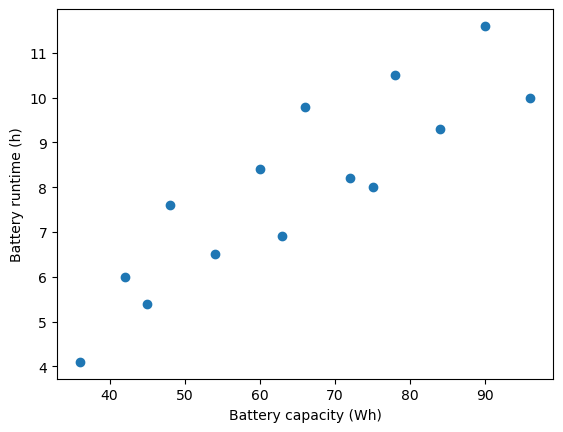

In [3]:

# Your scatterplot and Pearson correlation here
xcol = "battery_Wh"
ycol = "runtime_h"
plt.scatter(complete[xcol], complete[ycol])
plt.xlabel(laptop_labels[xcol])
plt.ylabel(laptop_labels[ycol])

r = complete[xcol].corr(complete[ycol])

### C. Restrict the range (1 pt)

Calculate the battery-capacity cutoffs at the quantiles specified in `laptop_settings`. Create `restricted` using `.loc[]` and `&` to keep capacities **between those cutoffs, including both endpoints**. Do not hard-code the cutoffs.

Display one table comparing the number of observations $n$ and the battery-capacity/runtime correlation $r$ for `complete` and `restricted`. Briefly report how $r$ changed.

**Answer:**
after restricting the capacity range, the r decreased by almost half so the linear correlation decreased. 

In [4]:
# Your data-derived cutoffs, Boolean filter, and n/r comparison here
lower_cutoff = complete["battery_Wh"].quantile(laptop_settings["lower_quantile"])
upper_cutoff = complete["battery_Wh"].quantile(laptop_settings["upper_quantile"])

restricted = complete.loc[
     (complete["battery_Wh"] >= lower_cutoff) &
     (complete["battery_Wh"] <= upper_cutoff)
 ]
comparison = pd.DataFrame({
    "n":[len(complete),len(restricted)],
    "r": [
        complete["battery_Wh"].corr(complete["runtime_h"]),
        restricted["battery_Wh"].corr(restricted["runtime_h"])
    ]
}, index = ["complete", "restricted"])
display(comparison)


                        
                        

,n,r
complete,14,0.878026
restricted,6,0.437600


## LE5-2. Cross-correlation matrix from a CSV file (3 pts)

Use the **Palmer Penguins** data in `data/penguins.csv`. Each row represents one penguin. Analyze the four physical measurements listed in `penguin_labels`; do not include species, island, sex, or year in the matrix.

Source: Horst, Hill, and Gorman, [palmerpenguins](https://allisonhorst.github.io/palmerpenguins/), with measurements collected by Kristen Gorman and Palmer Station LTER. [Variable definitions](https://allisonhorst.github.io/palmerpenguins/reference/penguins.html). The supplied CSV is the copy distributed with [plotnine](https://plotnine.org/reference/penguins.html); the data are licensed CC0. No additional package is needed to load the CSV.

### A. Load and prepare the data (1 pt)

Use `pd.read_csv()` to load `csv_path` into `penguins` and display its first few rows. Select `measurement_cols`, then drop rows missing **any of these four measurements**, storing the result as `penguin_complete`. Do not drop observations just because sex or another unused column is missing.

Report the number of rows loaded, retained, and excluded. Use the same `penguin_complete` observations throughout this exercise.

In [5]:
csv_path = Path("data/penguins.csv")
penguin_labels = {
    "bill_length_mm": "Bill length (mm)",
    "bill_depth_mm": "Bill depth (mm)",
    "flipper_length_mm": "Flipper length (mm)",
    "body_mass_g": "Body mass (g)",
}
measurement_cols = list(penguin_labels)

# Your pd.read_csv(), preview, complete-case selection, and counts here
penguins = pd.read_csv(csv_path)
display(penguins.head())
penguin_complete = penguins[measurement_cols].dropna()
rows_loaded = len(penguins)
rows_retained = len(penguin_complete)
rows_excluded = rows_loaded - rows_retained
print("rows loaded:", rows_loaded)
print("rows retained:", rows_retained)
print("rows excluded:", rows_excluded)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


rows loaded: 344
rows retained: 342
rows excluded: 2


### B. Calculate and display the matrix (1 pt)

Calculate the **Pearson cross-correlation matrix** for all four columns of `penguin_complete` and name it `corr_matrix`. Here, the matrix contains the pairwise correlations between the measurement columns, not correlations at time lags. Display it rounded to three decimal places, keeping the unrounded matrix for plotting and subsequent calculations.

**The heat-map code is provided below; do not rewrite it.** Run the function-definition cell, then use `ax = plot_correlation_heatmap(corr_matrix)` after calculating your matrix. The fixed scale maps **−1 to dark red, 0 to white, and +1 to dark blue**.

In [6]:
# Provided plotting code: run this cell unchanged.
def plot_correlation_heatmap(corr_matrix):
    """Plot the student's matrix on a fixed red–white–blue scale."""
    cmap = LinearSegmentedColormap.from_list(
        "correlation_rwb", ["darkred", "white", "darkblue"], N=257
    )  # An odd palette size makes the middle color exactly white.

    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(
        corr_matrix, cmap=cmap, vmin=-1, vmax=1, interpolation="nearest"
    )
    positions = np.arange(len(corr_matrix.columns))
    labels = [penguin_labels[column] for column in corr_matrix.columns]
    ax.set_xticks(positions, labels=labels, rotation=45, ha="right")
    ax.set_yticks(positions, labels=labels)
    ax.set_title("Palmer Penguins: Pearson correlation matrix", pad=14)

    for (row, col), value in np.ndenumerate(corr_matrix.to_numpy()):
        ax.text(
            col, row, f"{value:.2f}", ha="center", va="center",
            color="white" if abs(value) > 0.5 else "black",
        )

    fig.colorbar(image, ax=ax, label="Pearson r", ticks=[-1, -0.5, 0, 0.5, 1])
    fig.tight_layout()
    plt.show()
    return ax

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


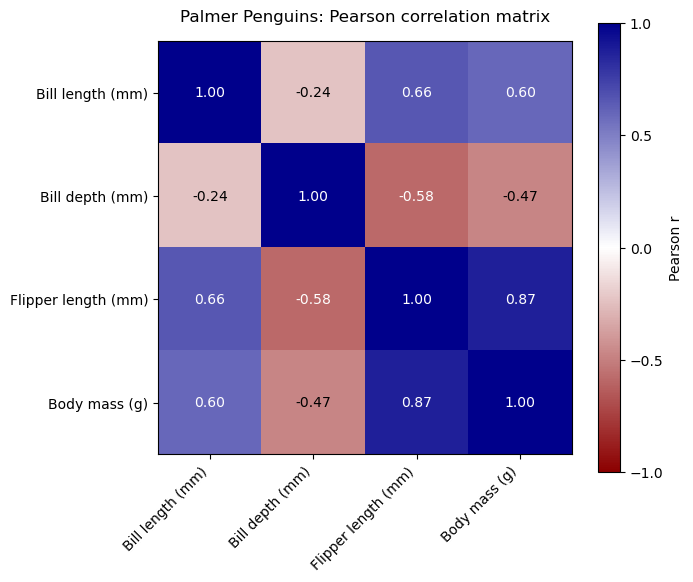

In [13]:
# Your corr_matrix calculation and rounded display here
corr_matrix = penguin_complete.corr(method="pearson")
display(corr_matrix.round(3))
ax = plot_correlation_heatmap(corr_matrix)
# After calculating corr_matrix, uncomment the following line:


### C. Select pairs and make a scatterplot (1 pt)

Use your matrix to identify the **strongest positive** and **strongest negative** correlations between distinct measurements. Ignore the diagonal and count each pair only once. Report both pairs and retrieve their correlations with `.loc[]`, rather than typing the correlation values by hand.

Make a scatterplot for whichever of these two pairs has the larger absolute correlation. Label the axes using `penguin_labels` and include its $r$ in the title.

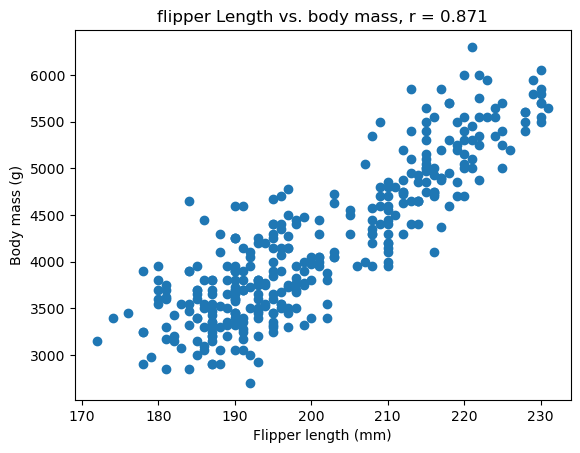

Strongest positive pair: ('flipper_length_mm', 'body_mass_g')
r = 0.8712017673060111
Strongest negative pair: ('bill_depth_mm', 'flipper_length_mm')
r = -0.5838512164654143


In [20]:
# Identify the two pairs and retrieve their r values from corr_matrix.
# Plot the pair with the larger absolute correlation.
positive_pair = ("flipper_length_mm", "body_mass_g")
negative_pair = ("bill_depth_mm", "flipper_length_mm")

r_positive = corr_matrix.loc[positive_pair[0], positive_pair[1]]
r_negative = corr_matrix.loc[negative_pair[0], negative_pair[1]]

xcol = positive_pair[0]
ycol=positive_pair[1]
plt.scatter(penguin_complete[xcol], penguin_complete[ycol])

plt.xlabel(penguin_labels[xcol])
plt.ylabel(penguin_labels[ycol])
plt.title(f"flipper Length vs. body mass, r = {r_positive:.3f}")

plt.show()
print("Strongest positive pair:", positive_pair)
print("r =", r_positive)

print("Strongest negative pair:", negative_pair)
print("r =", r_negative)

## LE5-3. Compare a curved pattern with an added observation (2 pts)

A process-development team records product yield at several temperatures. Each row is one run. `yield_pct` is the percentage of starting material recovered as the desired product.

### A. Plot the original runs (1 pt)

Plot temperature on the x-axis and yield on the y-axis, then calculate Pearson's $r$. Use a condition on `yield_pct` to display the run or runs with the highest observed yield. Briefly describe the plotted pattern.

**Answer:**
adding the unusualy observations drastically changed the r from a positive to a negative number 

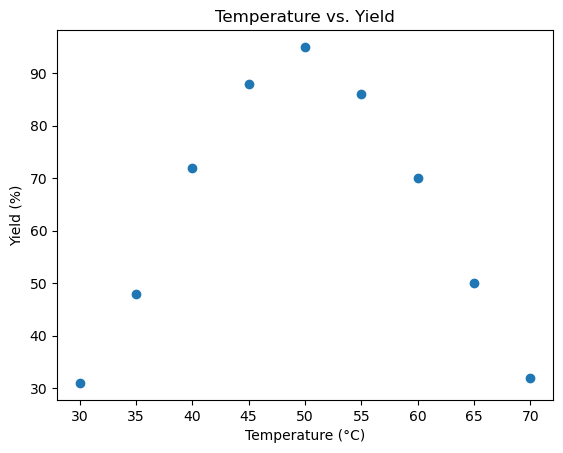

0.0075451107882686915


,temperature_C,yield_pct
4,50,95


In [21]:
runs = pd.DataFrame({
    "temperature_C": [30, 35, 40, 45, 50, 55, 60, 65, 70],
    "yield_pct": [31, 48, 72, 88, 95, 86, 70, 50, 32],
})

# Your scatterplot, Pearson correlation, and maximum-yield run selection here
plt.scatter(runs["temperature_C"], runs["yield_pct"])

plt.xlabel("Temperature (°C)")
plt.ylabel("Yield (%)")
plt.title("Temperature vs. Yield")
plt.show()
r_original = runs["temperature_C"].corr(runs["yield_pct"])
highest_yield = runs.loc[
    runs["yield_pct"] == runs["yield_pct"].max()
]
print(r_original)
display(highest_yield)

                                             

### B. Add one unusual observation (1 pt)

Use `pd.concat()` to combine `runs` and `extra_run` into a new DataFrame, `all_runs`; retain the original data.

Display one table comparing $n$ and $r$ for the original and combined data. Make a scatterplot of the combined data, marking the additional run with a different marker and adding a legend. Report the numerical change in $r$ (combined minus original).

,n,r
Original,9,0.007545
Combined,10,-0.558668


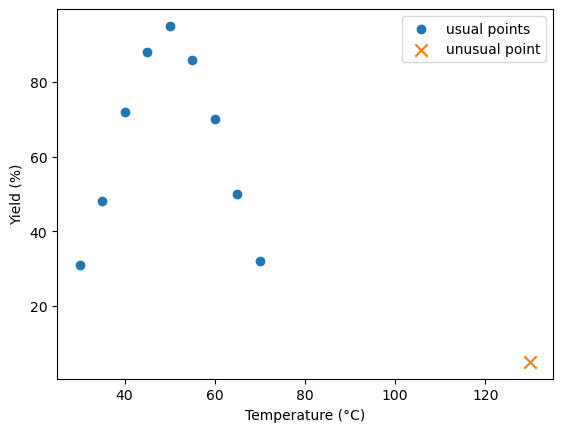

In [25]:
extra_run = pd.DataFrame({"temperature_C": [130], "yield_pct": [5]})

# Your combined data, n/r comparison, and scatterplot here
all_runs = pd.concat([runs, extra_run], ignore_index=True)

r_combined = all_runs["temperature_C"].corr(all_runs["yield_pct"])

comparison = pd.DataFrame({
    "n": [len(runs), len(all_runs)],
    "r": [r_original, r_combined]
}, index=["Original", "Combined"])

display(comparison)
plt.scatter(runs["temperature_C"], runs["yield_pct"],
            marker="o", label="usual points")

plt.scatter(extra_run["temperature_C"], extra_run["yield_pct"],
            marker="x", s=80, label="unusual point")
plt.xlabel("Temperature (°C)")
plt.ylabel("Yield (%)")
plt.legend()

## LE5-4. Write a function and use it twice (2 pts)

Each row below is one trainee in one of four workshops. The records give practice hours and an assembly assessment score on a 0–100 scale. These are synthetic observational records.

### A. Write and call your function (1 pt)

The individual and workshop-average analyses require the same scatterplot, count, and correlation. Write **`plot_and_summarize(data, title)`** to do that work once in a reusable function.

Your function must:

1. Create and display a **new scatterplot** of `practice_hours` on the x-axis and `assembly_score` on the y-axis. Label the axes **Practice hours (h)** and **Assembly score (0–100)**, and use the supplied `title`.
2. Calculate the number of rows $n$ and Pearson's $r$ from the supplied `data`.
3. **Return a `pd.Series`** with entries named `"n"` and `"r"`, rather than only printing them.

Use the `data` argument for every calculation and plot; do not refer to `trainees` or `workshop_means` inside the function. Do not hard-code the row count or correlation.

**First call:** Call your function on `trainees` with the title `"Individual trainees"`. Store its returned Series as `individual_summary` and display it. Write both the function body and the call yourself.

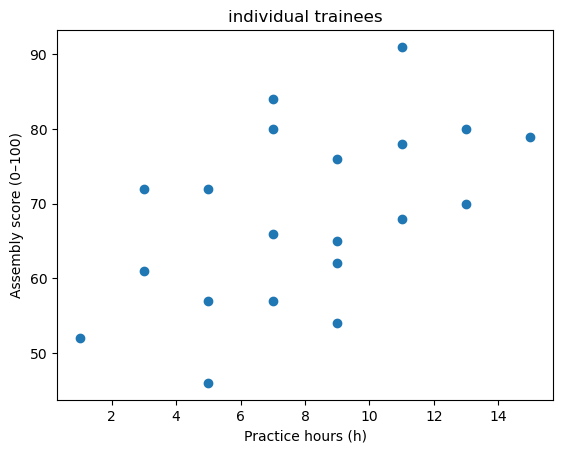

n    20.000000
r     0.516575
dtype: float64

In [26]:
trainees = pd.DataFrame({
    "workshop": ["A"] * 5 + ["B"] * 5 + ["C"] * 5 + ["D"] * 5,
    "practice_hours": [1, 3, 5, 7, 9, 3, 5, 7, 9, 11,
                       5, 7, 9, 11, 13, 7, 9, 11, 13, 15],
    "assembly_score": [52, 61, 46, 57, 54, 72, 57, 66, 62, 68,
                       72, 80, 65, 78, 70, 84, 76, 91, 80, 79],
})

def plot_and_summarize(data, title):
    """Plot practice hours versus score and return a Series containing n and r."""
    plt.scatter(data["practice_hours"], data["assembly_score"])
    
    plt.xlabel("Practice hours ")
    plt.ylabel("Assembly score ")
    plt.title(title)
    plt.show()
    
    n = len(data)
    r = data["practice_hours"].corr(data["assembly_score"])
    
    return pd.Series({"n": n, "r": r})


# First call: analyze trainees and store the result as individual_summary.
individual_summary = plot_and_summarize(
    trainees,
    "Individual trainees"
)
# Display the returned Series.
display(individual_summary)

### B. Reuse the function for workshop averages (1 pt)

Use `.groupby(...).agg(...)` to create `workshop_means`, with one row per workshop showing its trainee count, mean practice hours, and mean assembly score. Name the count column `trainee_count`, and keep the two mean columns named **`practice_hours`** and **`assembly_score`** so the same function can analyze them. Display this table.

**Second call:** Call the **same function** on `workshop_means` with the title `"Workshop averages"`. Store its returned Series as `workshop_summary`. The returned $n$ now counts workshop rows, not individual trainees.

Use `individual_summary` and `workshop_summary` to create one labeled comparison table containing $n$ and $r$. Do not duplicate the scatterplot or correlation code outside the function. Briefly report how $r$ changed after aggregation.

**Answer:**
after averaging the trainees the r increase to almost 1 so the linear association increased drastically. 

,trainee_count,practice_hours,assembly_score
workshop,,,
A,5,5.0,54.0
B,5,7.0,65.0
C,5,9.0,73.0
D,5,11.0,82.0


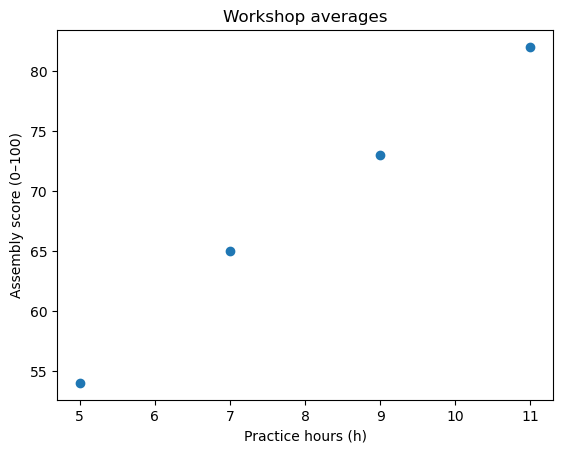

,n,r
Individual trainees,20.0,0.516575
Workshop averages,4.0,0.997880


In [27]:
# Create and display workshop_means using .groupby(...).agg(...).
# Keep the mean-column names practice_hours and assembly_score.

# Second call: analyze workshop_means and store the result as workshop_summary.

# Combine the two returned Series into a labeled n/r comparison table.
workshop_means = trainees.groupby("workshop").agg(
    trainee_count=("workshop", "size"),
    practice_hours=("practice_hours", "mean"),
    assembly_score=("assembly_score", "mean")
)

display(workshop_means)

workshop_summary = plot_and_summarize(
    workshop_means,
    "Workshop averages"
)

comparison = pd.DataFrame({
    "Individual trainees": individual_summary,
    "Workshop averages": workshop_summary
}).T

display(comparison)

## Session records

At the end of each working session, type **"make my record"** in the chat and paste the block it produces into the cell below. If you work across several sessions, paste each new block underneath the previous one.

<!-- Paste your session record blocks in this cell, one after another. -->

*(session records go here)*
{
  "schema_version": "engr-tutor-export-2",
  "assignment": "WA5",
  "export_n": 1,
  "session_date": "2026-10-07",
  "messages": [
    {"i": 1, "who": "student", "text": "i am ready to start"},
    {"i": 2, "who": "tutor", "served": ["how_to_use", "a5_preamble", "a5_setup", "a5_le5_1"], "text": "You are starting with LE5-1A. Two moves: keep the three `feature_cols` columns and drop every row that is missing any of them, storing that as `complete`; then two counts, both calculated. [trimmed]"},
    {"i": 3, "who": "student", "text": "okay what function could be used to make the complete section"},
    {"i": 4, "who": "tutor", "text": "The function you want is `.dropna()`. It removes rows that contain missing values (`NaN`), and its arguments control which rows count as \"missing.\" [trimmed]"},
    {"i": 5, "who": "student", "text": "okay so complete = laptops[feature_cols].dropna() and then fined the retained and excluded", "code": true},
    {"i": 6, "who": "tutor", "text": "That line is right: it selects the three `feature_cols` columns first, then drops any row missing one of them, and stores the result as `complete`. [trimmed]"},
    {"i": 7, "who": "student", "text": "i got 14 laptops retained and 2 laptops excluded and then this is my scatter [screenshot of 1B cell and scatterplot attached]", "code": true},
    {"i": 8, "who": "tutor", "text": "Your 14 retained and 2 excluded are correct. The scatter matches what the prompt asks for. One thing to fix: your cell's last line is `r = ...`, which stores the value but doesn't show it, so print it. [trimmed]"},
    {"i": 9, "who": "student", "text": "I am going to do all the written portions of the assignment at the end can we move onto the next part please"},
    {"i": 10, "who": "tutor", "text": "Sounds good, you can come back to the 1B sentence whenever you like. [LE5-1C prompt and `.quantile()` / `.loc[]` syntax example shown] [trimmed]"},
    {"i": 11, "who": "student", "text": "okay so start with making a lower and uper quantile?"},
    {"i": 12, "who": "tutor", "text": "Yes, that's the right first move. You need two cutoffs, one for each level in `laptop_settings`, and both should come from the battery-capacity column of `complete`. [trimmed]"},
    {"i": 13, "who": "student", "text": "ower_cutoff = complete[\"batter_wh\"].quantile(laptop_settings[\"lower_quantile\"])\nupper_cutoff = complete[\"batter_wh\"].quantile(laptop_settings[\"upper_quantile\"])", "code": true},
    {"i": 14, "who": "tutor", "text": "You have the right structure: each cutoff calls `.quantile()` on a column of `complete` and reads its level from `laptop_settings`, so nothing is typed in. Two things to check: the column name spelling and the clipped first line. [trimmed]"},
    {"i": 15, "who": "student", "text": "would the complete lowk contain a boolean"},
    {"i": 16, "who": "tutor", "text": "No, `complete` holds your numbers (battery capacity, mass, runtime), not Booleans. A Boolean shows up when you make a comparison. [trimmed]"},
    {"i": 17, "who": "student", "text": "so would the mask be osmething ike complet[,\".....\"] >+ cutoff &...."},
    {"i": 18, "who": "tutor", "text": "You have the right idea: one comparison against each cutoff, joined with `&`. A few fixes to the shape of what you typed: the column syntax, `>=`, and parentheses. [trimmed]"},
    {"i": 19, "who": "student", "text": "okay  and for the comprison should I use a dataframe"},
    {"i": 20, "who": "tutor", "text": "Yes, a DataFrame is a good fit. The prompt asks for one table with a row for `complete` and a row for `restricted`. [trimmed]"},
    {"i": 21, "who": "student", "text": "[screenshot of 1C cell attached]", "code": true},
    {"i": 22, "who": "tutor", "text": "Your structure is right across the whole cell. The cell won't run yet, though: column name spelling in several places, `pd.dataframe`, and `restriced`. [trimmed]"},
    {"i": 23, "who": "student", "text": "this was my output [screenshot of n/r comparison table attached]"},
    {"i": 24, "who": "tutor", "text": "Your table matches my own check of the numbers: n is 14 and 6, and r is about 0.878 for `complete` and about 0.438 for `restricted`. [trimmed]"},
    {"i": 25, "who": "student", "text": "move on please"},
    {"i": 26, "who": "tutor", "served": ["a5_le5_2"], "text": "You are starting with LE5-2A. Before anything else, make sure `penguins.csv` sits in a `data/` folder beside your notebook. [trimmed]"},
    {"i": 27, "who": "student", "text": "what function should I start with"},
    {"i": 28, "who": "tutor", "text": "Start with `pd.read_csv()`. It reads a CSV file and returns a DataFrame, and its first argument is the path to the file. [trimmed]"},
    {"i": 29, "who": "student", "text": "what does the .dropna function do"},
    {"i": 30, "who": "tutor", "text": "`.dropna()` removes missing values from a DataFrame. By default it drops every row that has at least one `NaN` in it, and it returns a new DataFrame. [trimmed]"},
    {"i": 31, "who": "student", "text": "this were my outputs: [screenshot of penguins preview and counts attached]", "code": true},
    {"i": 32, "who": "tutor", "text": "Your counts match my own check of the file: 344 loaded, 342 retained, 2 excluded. [trimmed]"},
    {"i": 33, "who": "student", "text": "next"},
    {"i": 34, "who": "tutor", "text": "You already have the LE5-2B text from the block I served earlier, so here is where to start. One call on `penguin_complete` gives the whole matrix, and you store it unrounded as `corr_matrix`. [trimmed]"},
    {"i": 35, "who": "student", "text": "should i just use the .corr function"},
    {"i": 36, "who": "tutor", "text": "Yes, `.corr()` is the right tool. Call it on the whole four-column DataFrame, `penguin_complete`, and it returns the full Pearson matrix in one step. [trimmed]"},
    {"i": 37, "who": "student", "text": "okay this is what I got: [screenshot of corr_matrix cell and rounded matrix attached]", "code": true},
    {"i": 38, "who": "tutor", "text": "Your matrix matches my own check, and the code does what the prompt asks: `corr_matrix` is stored unrounded and `.round(3)` appears only inside `display()`. The heat-map call is still commented out. [trimmed]"},
    {"i": 39, "who": "student", "text": "```\nNameError: name 'plot_correlation_heatmap' is not defined\n```", "code": true},
    {"i": 40, "who": "tutor", "text": "That `NameError` means Python hasn't seen the function yet. The definition cell has to run before the call. [trimmed]"},
    {"i": 41, "who": "student", "text": "[screenshot of heat map attached]", "code": true},
    {"i": 42, "who": "tutor", "text": "That's the heat map drawn correctly: the definition cell ran, the call worked, and the cell values and colors match the matrix you displayed earlier. [LE5-2C orientation, `.loc[]` syntax example] [trimmed]"},
    {"i": 43, "who": "student", "text": "[screenshot of the LE5-2C prompt and still-empty cell attached]"},
    {"i": 44, "who": "tutor", "text": "That screenshot shows your 2C cell is still just the two comment lines, so nothing is wrong yet. Which two pairs do you pick? [trimmed]"},
    {"i": 45, "who": "student", "text": "flipper length and body mass"},
    {"i": 46, "who": "tutor", "text": "Flipper length and body mass is the strongest positive pair, so that one is right. You still need the strongest negative pair.

## Before you submit

1. **Restart Kernel and Run All Cells** and confirm that every cell runs without errors.
2. Confirm that all calculations, tables, and plots are visible in the saved notebook.
3. Confirm that your written answers are complete and your session record block(s) are pasted above.
4. Save the completed `.ipynb` file.
5. Submit the `.ipynb` file in Canvas.